<a href="https://colab.research.google.com/github/vera2005/MLCV_course1/blob/main/Lesson3/Lesson3_full.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

0. Импорты

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Воспроизводимость
np.random.seed(42)
tf.random.set_seed(42)

Вспомогательные функции

- plot_history — рисует графики loss и accuracy для train и val, чтобы глазами увидеть переобучение.

- compute_metrics — считает accuracy, precision, recall и F1 (macro и weighted) на тесте и возвращает словарь для сравнения моделей.

- show_classification_report — печатает детальный отчёт по метрикам для каждого класса отдельно.

- show_confusion_matrix — рисует матрицу ошибок в виде heatmap, чтобы видеть, какие классы модель путает.

In [2]:
def plot_history(history, title):
    """Строит графики loss и accuracy для train и val."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['loss'], label='train', linewidth=2)
    axes[0].plot(history.history['val_loss'], label='val', linewidth=2)
    axes[0].set_title(f'{title} — Loss')
    axes[0].set_xlabel('Эпоха')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(history.history['accuracy'], label='train', linewidth=2)
    axes[1].plot(history.history['val_accuracy'], label='val', linewidth=2)
    axes[1].set_title(f'{title} — Accuracy')
    axes[1].set_xlabel('Эпоха')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


def compute_metrics(model, x_test, y_test_true, name):
    """
    Считает метрики: accuracy, precision, recall, F1 (macro и weighted).
    Возвращает словарь с метриками и массив предсказаний.
    """
    y_pred_prob = model.predict(x_test, verbose=0)
    y_pred = np.argmax(y_pred_prob, axis=1)

    result = {
        'name':        name,
        'accuracy':    accuracy_score(y_test_true, y_pred),
        'precision':   precision_score(y_test_true, y_pred,
                                       average='macro', zero_division=0),
        'recall':      recall_score(y_test_true, y_pred,
                                    average='macro', zero_division=0),
        'f1_macro':    f1_score(y_test_true, y_pred,
                                average='macro', zero_division=0),
        'f1_weighted': f1_score(y_test_true, y_pred,
                                average='weighted', zero_division=0),
        'y_pred':      y_pred
    }

    print(f"\n=== {name} ===")
    print(f"Accuracy:         {result['accuracy']:.4f}")
    print(f"Precision macro:  {result['precision']:.4f}")
    print(f"Recall macro:     {result['recall']:.4f}")
    print(f"F1 macro:         {result['f1_macro']:.4f}")
    print(f"F1 weighted:      {result['f1_weighted']:.4f}")

    return result


def show_classification_report(y_test_true, y_pred, name):
    """Печатает детальный отчёт по каждому классу."""
    print(f"\n--- Classification report: {name} ---")
    print(classification_report(y_test_true, y_pred, digits=4))


def show_confusion_matrix(y_test_true, y_pred, title, cmap='Blues'):
    """Рисует confusion matrix."""
    cm = confusion_matrix(y_test_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                cbar=False, square=True)
    plt.title(title)
    plt.xlabel('Предсказано')
    plt.ylabel('Истина')
    plt.tight_layout()
    plt.show()

**Precision** — «из тех, кого я назвал +, сколько реально +». Насколько можно верить, когда модель говорит «да».

**Recall** — «из всех реальных +, сколько я нашёл». Сколько пропустил.

**F1** — «баланс между precision и recall». Одним числом, когда важно и не ошибиться, и не пропустить.

**Аналогия для запоминания (рыбалка)**:
Precision — «из всего, что я вытащил из пруда, сколько реально рыба, а не мусор?»

Recall — «из всей рыбы в пруду, сколько я поймал?»

1. Загрузка данных

In [3]:
(x_train_full, y_train_full), (x_test, y_test) = mnist.load_data()


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


2. Подготовка данных

In [4]:
# Нормализация: пиксели были 0..255 → станут 0..1
x_train_full = x_train_full / 255.0
x_test = x_test / 255.0

# One-hot encoding меток
y_train_full_cat = to_categorical(y_train_full, 10)
y_test_cat = to_categorical(y_test, 10)

# ВАЖНО: специально берём маленькую выборку,
# чтобы вызвать переобучение у базовой модели
x_train = x_train_full[:3000]
y_train = y_train_full_cat[:3000]

x_val = x_train_full[3000:6000]
y_val = y_train_full_cat[3000:6000]

print(f"Train: {x_train.shape}")
print(f"Val:   {x_val.shape}")
print(f"Test:  {x_test.shape}")
print(f"Классов: {y_train_full_cat.shape[1]}")

Train: (3000, 28, 28)
Val:   (3000, 28, 28)
Test:  (10000, 28, 28)
Классов: 10


3. Создание базовой модели

Без борьбы с переобучением и усложненной архитектурой

Epoch 1/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8270 - loss: 0.5936 - val_accuracy: 0.9010 - val_loss: 0.3345
Epoch 2/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9253 - loss: 0.2327 - val_accuracy: 0.9287 - val_loss: 0.2456
Epoch 3/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.9607 - loss: 0.1358 - val_accuracy: 0.9243 - val_loss: 0.2447
Epoch 4/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9787 - loss: 0.0712 - val_accuracy: 0.9337 - val_loss: 0.2332
Epoch 5/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9903 - loss: 0.0391 - val_accuracy: 0.9363 - val_loss: 0.2323
Epoch 6/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9940 - loss: 0.0219 - val_accuracy: 0.9367 - val_loss: 0.2558
Epoch 7/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9943 - loss: 0.0245 - val_accuracy: 0.9323 - val_loss: 0.2621
Epoch 8/50
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9953 - loss: 0.0140 - val_accuracy: 0.9377 - v

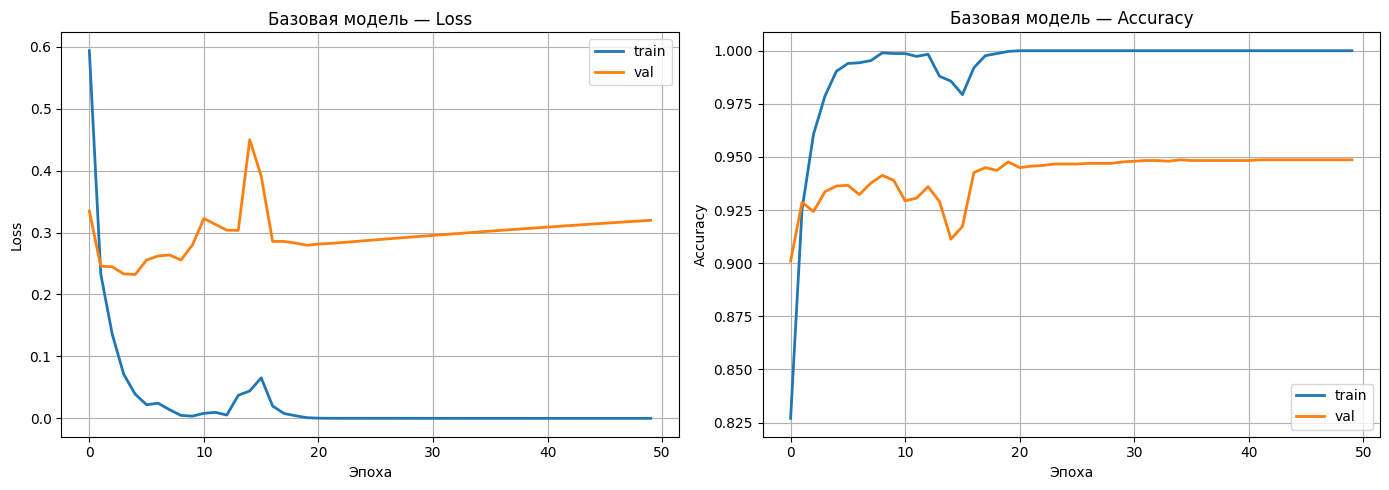

In [6]:

model_base = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),   # 28×28 → 784
    layers.Dense(512, activation='relu'),   # скрытый слой
    layers.Dense(512, activation='relu'),   # скрытый слой
    layers.Dense(10, activation='softmax')  # выход: 10 классов
])

model_base.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_base = model_base.fit(
    x_train, y_train,
    epochs=50,                  # много эпох → переобучение
    batch_size=32,
    validation_data=(x_val, y_val),
)

# Графики обучения
plot_history(history_base, "Базовая модель")

4. Анализ результатов

In [7]:
# Метрики на тесте
result_base = compute_metrics(model_base, x_test, y_test, "Базовая модель")


=== Базовая модель ===
Accuracy:         0.9434
Precision macro:  0.9427
Recall macro:     0.9427
F1 macro:         0.9427
F1 weighted:      0.9433


In [8]:
# Детальный отчёт по классам
show_classification_report(y_test, result_base['y_pred'], "Базовая модель")


--- Classification report: Базовая модель ---
              precision    recall  f1-score   support

           0     0.9612    0.9847    0.9728       980
           1     0.9790    0.9877    0.9833      1135
           2     0.9422    0.9322    0.9372      1032
           3     0.9485    0.9307    0.9395      1010
           4     0.9153    0.9460    0.9304       982
           5     0.9324    0.9283    0.9303       892
           6     0.9479    0.9489    0.9484       958
           7     0.9499    0.9407    0.9453      1028
           8     0.9230    0.9107    0.9168       974
           9     0.9279    0.9177    0.9228      1009

    accuracy                         0.9434     10000
   macro avg     0.9427    0.9427    0.9427     10000
weighted avg     0.9434    0.9434    0.9433     10000



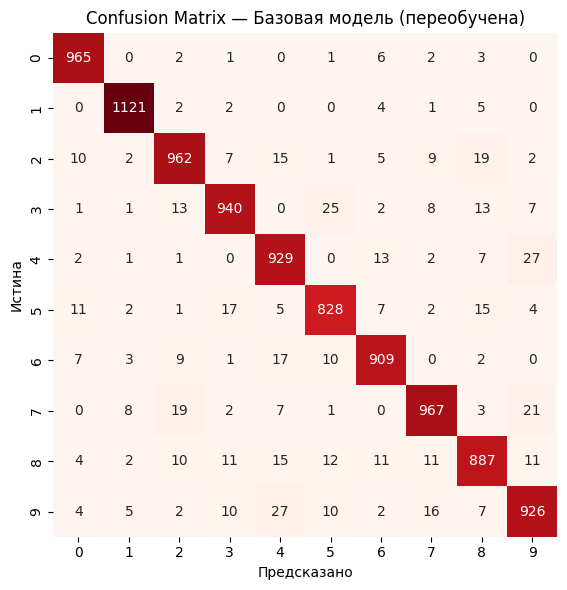

In [9]:
# Confusion matrix
show_confusion_matrix(
    y_test, result_base['y_pred'],
    title='Confusion Matrix — Базовая модель (переобучена)',
    cmap='Reds'
)

5. Создание регуляризированной модели, которую мы попробуем защитить от переобучения и добиться от нее лучших метрик на тестовых данных

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 24: early stopping
Restoring model weights from the end of the best epoch: 19.


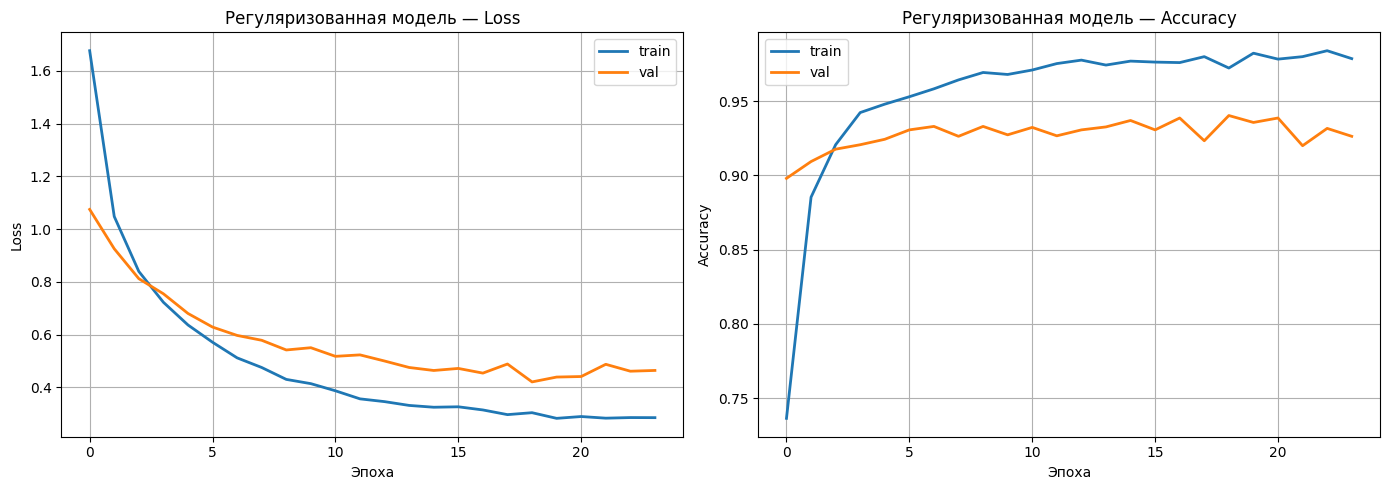

In [10]:

model_reg = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),

    layers.Dense(512, activation='relu',
                 kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.4),

    layers.Dense(512, activation='relu',
                 kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.4),

    layers.Dense(10, activation='softmax')
])

model_reg.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# EarlyStopping: остановка, когда val_loss перестал падать
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history_reg = model_reg.fit(
    x_train, y_train,
    epochs=50,
    batch_size=32,
    validation_data=(x_val, y_val),
    callbacks=[early_stop],
    verbose=0
)

# Графики обучения
plot_history(history_reg, "Регуляризованная модель")

6. Анализ результатов регуляризированной модели

In [11]:
# Метрики на тесте
result_reg = compute_metrics(model_reg, x_test, y_test, "Регуляризованная модель")


=== Регуляризованная модель ===
Accuracy:         0.9387
Precision macro:  0.9382
Recall macro:     0.9381
F1 macro:         0.9379
F1 weighted:      0.9386


In [12]:
# Детальный отчёт по классам
show_classification_report(y_test, result_reg['y_pred'], "Регуляризованная модель")


--- Classification report: Регуляризованная модель ---
              precision    recall  f1-score   support

           0     0.9533    0.9786    0.9658       980
           1     0.9706    0.9877    0.9790      1135
           2     0.9305    0.9341    0.9323      1032
           3     0.9302    0.9366    0.9334      1010
           4     0.9392    0.9287    0.9339       982
           5     0.9065    0.9451    0.9254       892
           6     0.9470    0.9509    0.9490       958
           7     0.9575    0.9202    0.9385      1028
           8     0.9425    0.8747    0.9073       974
           9     0.9049    0.9247    0.9147      1009

    accuracy                         0.9387     10000
   macro avg     0.9382    0.9381    0.9379     10000
weighted avg     0.9389    0.9387    0.9386     10000



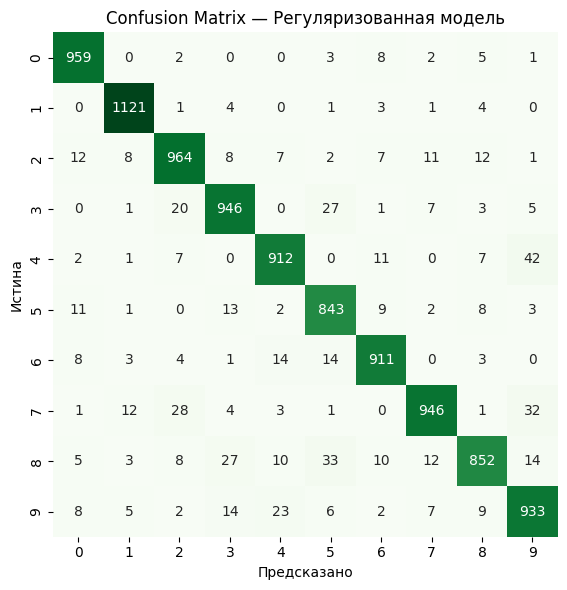

In [13]:
# Confusion matrix
show_confusion_matrix(
    y_test, result_reg['y_pred'],
    title='Confusion Matrix — Регуляризованная модель',
    cmap='Greens'
)

7. Сравнение метрик

In [14]:


print(f"\n{'Метрика':<20}{'Базовая':<15}{'Регуляриз.':<15}{'Δ':<15}")
print("-" * 65)

metrics_to_compare = ['accuracy', 'precision', 'recall', 'f1_macro', 'f1_weighted']

for m in metrics_to_compare:
    base_val = result_base[m]
    reg_val  = result_reg[m]
    delta    = reg_val - base_val
    sign     = '+' if delta >= 0 else ''
    print(f"{m:<20}{base_val:<15.4f}{reg_val:<15.4f}{sign}{delta:<15.4f}")


Метрика             Базовая        Регуляриз.     Δ              
-----------------------------------------------------------------
accuracy            0.9434         0.9387         -0.0047        
precision           0.9427         0.9382         -0.0045        
recall              0.9427         0.9381         -0.0046        
f1_macro            0.9427         0.9379         -0.0047        
f1_weighted         0.9433         0.9386         -0.0048        


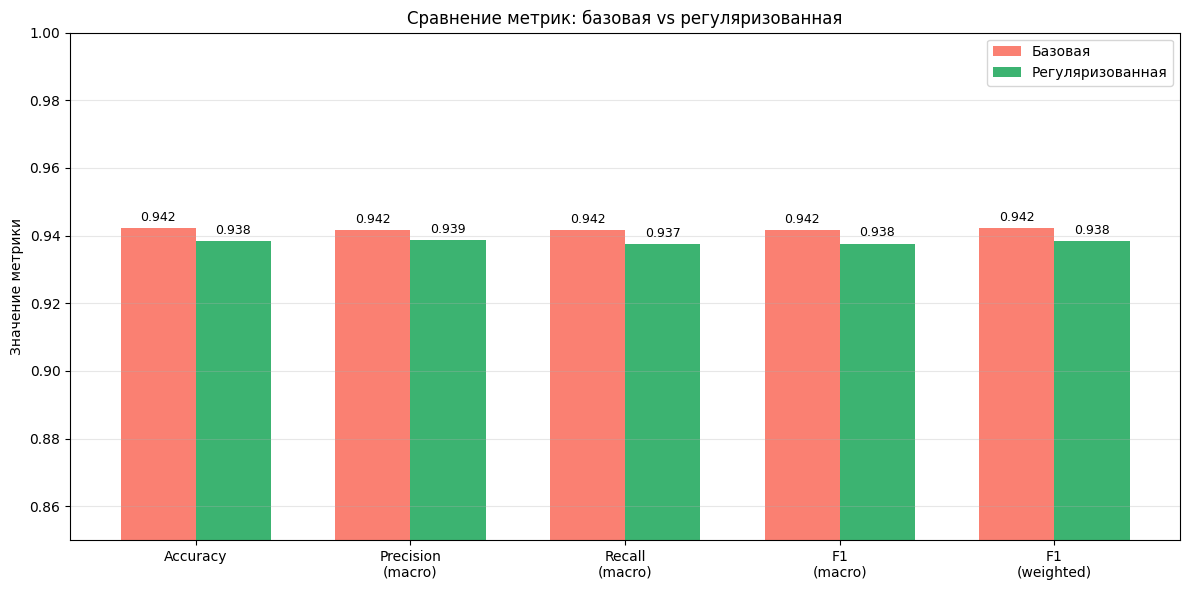

In [ ]:
# Визуальное сравнение метрик
labels = ['Accuracy', 'Precision\n(macro)', 'Recall\n(macro)',
          'F1\n(macro)', 'F1\n(weighted)']

base_values = [result_base[m] for m in metrics_to_compare]
reg_values  = [result_reg[m]  for m in metrics_to_compare]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width/2, base_values, width, label='Базовая', color='salmon')
bars2 = ax.bar(x + width/2, reg_values,  width, label='Регуляризованная', color='mediumseagreen')

ax.set_ylabel('Значение метрики')
ax.set_title('Сравнение метрик: базовая vs регуляризованная')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0.85, 1.0)
ax.legend()
ax.grid(axis='y', alpha=0.3)

for bars in (bars1, bars2):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

Сравнение кривых обучения

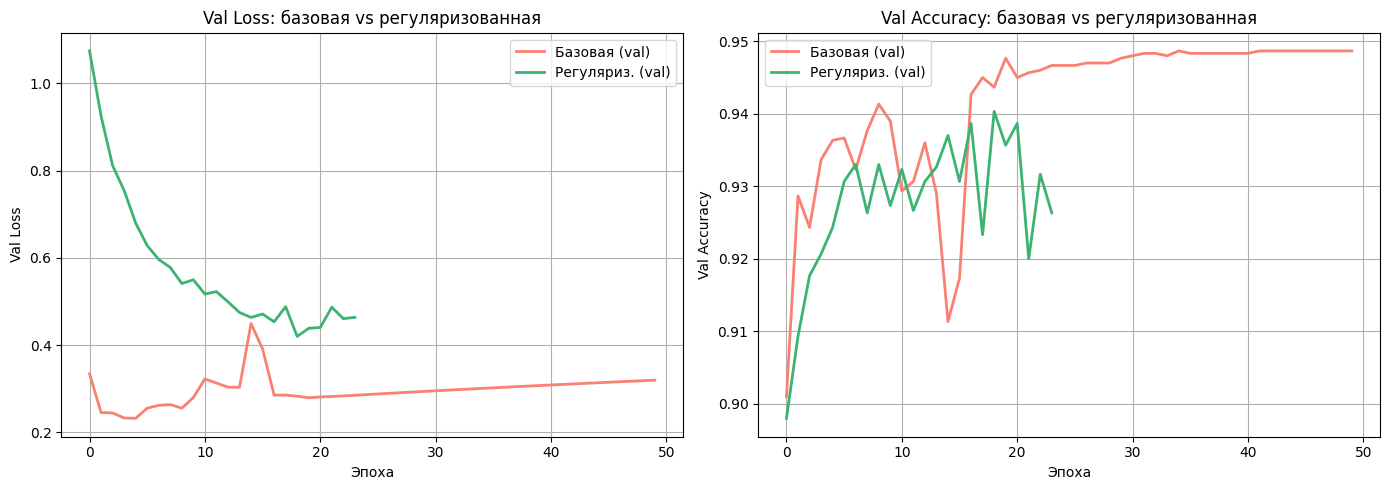

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history_base.history['val_loss'], label='Базовая (val)', linewidth=2, color='salmon')
axes[0].plot(history_reg.history['val_loss'],  label='Регуляриз. (val)', linewidth=2, color='mediumseagreen')
axes[0].set_title('Val Loss: базовая vs регуляризованная')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('Val Loss')
axes[0].legend()
axes[0].grid(True)

# Accuracy
axes[1].plot(history_base.history['val_accuracy'], label='Базовая (val)', linewidth=2, color='salmon')
axes[1].plot(history_reg.history['val_accuracy'],  label='Регуляриз. (val)', linewidth=2, color='mediumseagreen')
axes[1].set_title('Val Accuracy: базовая vs регуляризованная')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('Val Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()